# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- Устройство: Google Colab, GPU Tesla T4; torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0. Финальный прогон - Restart & Run All с `FAST_MODE = False`.
- Модель: [`cointegrated/rubert-tiny2`](https://huggingface.co/cointegrated/rubert-tiny2), revision `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT.
- Датасет: [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural) (`Babelscape/wikineural`), русская часть (`train_ru` / `val_ru` / `test_ru`), лицензия CC BY-NC-SA 4.0.
- Бонусы: 6.2 (сравнение с [`FacebookAI/xlm-roberta-base`](https://huggingface.co/FacebookAI/xlm-roberta-base), revision `e73636d4f797dec63c3081bb6ed5c7b0bb3f2089`, MIT), 6.3, 6.4, 6.5.
- Время обучения: rubert-tiny2 - 297 с, абляция с замороженным энкодером - 170 с, xlm-roberta-base - 1746 с.
- Источники: документация transformers, datasets и seqeval, карточки модели и датасета.
- Нерешенные задачи: нет.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}
BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** `rubert-tiny2` - маленький BERT для русского (в карточке `language: ru`, лицензия MIT): 3 слоя, hidden 312, словарь 83 828 сабвордов, 29.1M параметров, веса 112 MB; прямой проход батча 32 x 64 на T4 - около 5 мс, поэтому полный train из 92 тыс. предложений за 3 эпохи обучается за 5 минут. Альтернативы: `DeepPavlov/rubert-base-cased` (~180M, 12 слоев, hidden 768) - в 6 раз больше и медленнее, ожидаемо точнее, но в карточке на Hub не указана лицензия; `FacebookAI/xlm-roberta-base` (277M, MIT, 100 языков) - в 9.5 раз больше, в 6.2 она дала F1 0.901 против 0.860 ценой в 5.9 раза более долгого обучения. Без фиксации `revision` ноутбук скачает то, на что сейчас указывает `main`: владелец может перезалить веса, токенизатор или конфиг (у этой модели репозиторий обновлялся 2025-12-30), и через полгода изменятся числа, словарь и разбиение на сабворды (а значит, выравнивание меток), или загрузка вообще упадет из-за удаленного файла или несовместимого конфига.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def count(module):
        return sum(p.numel() for p in module.parameters())

    base = getattr(model, model.base_model_prefix)
    layers = [count(layer) for layer in base.encoder.layer]
    embeddings, head = count(base.embeddings), count(model.classifier)
    other = count(model) - embeddings - sum(layers) - head
    return dict(embeddings=embeddings, encoder=sum(layers), head=head, other=other, layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
for i in range(len(demo_texts)):
    print(enc.tokens(i))
print({k: tuple(v.shape) for k, v in enc.items()})
print('hidden_states:', len(out.hidden_states), 'x', tuple(out.hidden_states[0].shape))
print('logits:', tuple(out.logits.shape))

['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']
{'input_ids': (2, 11), 'token_type_ids': (2, 11), 'attention_mask': (2, 11)}
hidden_states: 4 x (2, 11, 312)
logits: (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 5.3 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Слова токенизатор режет на сабворды и добавляет спецтокены: `input_ids`, `token_type_ids`, `attention_mask` формы `(2, 11)`. Эмбеддинги (сабворд + позиция + тип, LayerNorm) дают `hidden_states[0]` формы `(2, 11, 312)`, затем 3 слоя энкодера - еще три тензора `(2, 11, 312)` (всего 4 `hidden_states`), голова `Linear(312, 7)` к каждому токену - logits `(2, 11, 7)`. Больше всего параметров в эмбеддингах: 26.79M (92.1%), из них 83 828 x 312 = 26.15M - таблица словаря; энкодер - 2.30M (7.9%, по 767 184 на слой), голова - 2 191 = 312 x 7 + 7. Словарь большой, а hidden маленький, поэтому таблица эмбеддингов перевешивает все слои. Токены обмениваются информацией только в слоях энкодера (self-attention); эмбеддинги и голова обрабатывают каждый токен независимо. `T = 11` больше числа слов (6), потому что слова режутся на сабворды (`Чайк ##овский`, `Вот ##кинс ##ке`, `IT ##M ##O`), добавляются `[CLS]` и `[SEP]`, а второе предложение дополняется `[PAD]` до длины первого.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None
raw = load_dataset(DATASET_ID, data_files={'train': 'data/train_ru-*.parquet', 'validation': 'data/val_ru-*.parquet',
                                           'test': 'data/test_ru-*.parquet'}).remove_columns('lang')
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
raw

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 11580
    })
})

type           train  validation        test  share train
LOC           71,090       8,851       8,596        48.0%
MISC          23,594       2,642       2,962        15.9%
ORG           20,236       2,710       3,051        13.7%
PER           33,282       4,007       3,489        22.5%

train       предложений 92,320  слов: среднее 19.6, медиана 17, max 256  сущностей на предложение 1.61  без сущностей 0.0%
validation  предложений 11,540  слов: среднее 18.8, медиана 17, max 107  сущностей на предложение 1.58  без сущностей 0.0%
test        предложений 11,580  слов: среднее 18.8, медиана 17, max 124  сущностей на предложение 1.56  без сущностей 0.0%

длина спанов в словах (train): среднее, доли 1 / 2 / 3 / 4+
LOC     1.12   90.3%    8.0%    1.2%    0.5%
MISC    1.54   72.6%   13.4%    7.6%    6.4%
ORG     1.62   62.4%   21.2%   11.6%    4.8%
PER     1.37   68.7%   26.2%    4.7%    0.4%


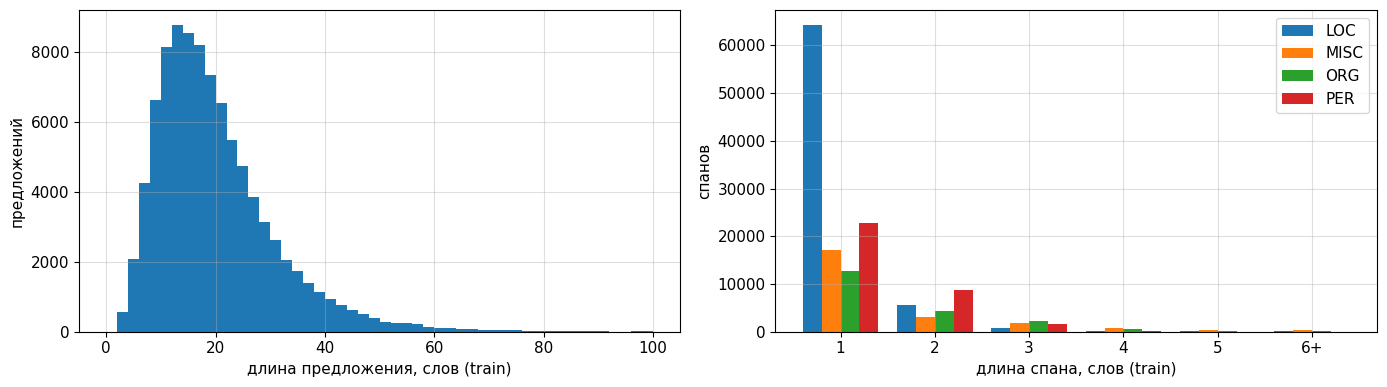

In [14]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
def word_spans(tag_ids):
    spans, cur = [], None
    for name in (LABEL_NAMES[i] for i in tag_ids):
        if name == 'O':
            cur = None
            continue
        if name.startswith('B-') or cur is None or cur[0] != name[2:]:
            cur = [name[2:], 0]
            spans.append(cur)
        cur[1] += 1
    return spans


ent_counts, sent_lens, no_ent, span_lens = {}, {}, {}, collections.defaultdict(list)
for split, ds in raw.items():
    ent_counts[split], sent_lens[split], no_ent[split] = collections.Counter(), [], 0
    for tags in ds['ner_tags']:
        spans = word_spans(tags)
        sent_lens[split].append(len(tags))
        no_ent[split] += not spans
        for typ, length in spans:
            ent_counts[split][typ] += 1
            if split == 'train':
                span_lens[typ].append(length)

types = sorted(span_lens)
print(f'{"type":<8}' + ''.join(f'{s:>12}' for s in raw) + f'{"share train":>13}')
for t in types:
    print(f'{t:<8}' + ''.join(f'{ent_counts[s][t]:>12,}' for s in raw)
          + f'{ent_counts["train"][t] / sum(ent_counts["train"].values()):>13.1%}')
print()
for split in raw:
    lens = np.array(sent_lens[split])
    print(f'{split:<11} предложений {len(lens):>6,}  слов: среднее {lens.mean():.1f}, медиана {np.median(lens):.0f}, '
          f'max {lens.max()}  сущностей на предложение {sum(ent_counts[split].values()) / len(lens):.2f}  '
          f'без сущностей {no_ent[split] / len(lens):.1%}')
print('\nдлина спанов в словах (train): среднее, доли 1 / 2 / 3 / 4+')
for t in types:
    lens = np.array(span_lens[t])
    print(f'{t:<6}{lens.mean():6.2f}  ' + '  '.join(f'{np.mean(lens == k):6.1%}' for k in (1, 2, 3)) + f'  {np.mean(lens >= 4):6.1%}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.hist(sent_lens['train'], bins=range(0, 102, 2))
ax1.set_xlabel('длина предложения, слов (train)')
ax1.set_ylabel('предложений')
ax2.hist([np.minimum(span_lens[t], 6) for t in types], bins=np.arange(0.5, 7), label=types)
ax2.set_xticks(range(1, 7), ['1', '2', '3', '4', '5', '6+'])
ax2.set_xlabel('длина спана, слов (train)')
ax2.set_ylabel('спанов')
ax2.legend()
for ax in (ax1, ax2):
    ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WikiNEuRal (Babelscape, Tedeschi et al., 2021, Findings of EMNLP), лицензия CC BY-NC-SA 4.0. Разметка автоматическая («silver»): предложения из Википедии, сущности найдены по внутренним ссылкам с помощью базы знаний и нейросетевой модели, вручную не проверялись. Типы PER / ORG / LOC / MISC; сплиты 92 320 / 11 540 / 11 580 предложений, в train 148 202 сущности: LOC 71 090 (48.0%), PER 33 282 (22.5%), MISC 23 594 (15.9%), ORG 20 236 (13.7%) - редкие ORG и MISC, LOC доминирует. Особенности: в каждом предложении есть хотя бы одна сущность (0.0% без сущностей, в среднем 1.6), поэтому модель не видит текстов без сущностей и может давать лишние срабатывания; спаны короткие (LOC в среднем 1.12 слова, 90% однословные; ORG 1.62 и MISC 1.54, у них 4.8% и 6.4% спанов длиннее 3 слов); предложения в среднем 19.6 слова (медиана 17, максимум 256). Шум разметки: 3 210 предложений train (3.5%) содержат `I-` без `B-`, а в разборе ошибок (5.1) видны неполные и сомнительные спаны.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, typ = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O' or tag.startswith('B-') or tag[2:] != typ:
            if typ is not None:
                spans.append((start, i, typ))
            start, typ = (None, None) if tag == 'O' else (i, tag[2:])
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, typ in spans:
        tags[start] = 'B-' + typ
        for i in range(start + 1, end):
            tags[i] = 'I-' + typ
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev:
            labels.append(word_labels[w])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        prev = w
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
Path('data').mkdir(exist_ok=True)
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for tokens, tags in zip(ds['tokens'], ds['ner_tags']):
            spans = bio_to_spans([LABEL_NAMES[i] for i in tags])
            f.write(json.dumps(dict(tokens=tokens, spans=spans), ensure_ascii=False) + '\n')
    n_lines = n_same = n_spans_only = n_spans = 0
    with path.open(encoding='utf-8') as f:
        for line, tags in zip(f, ds['ner_tags']):
            rec = json.loads(line)
            spans = [tuple(s) for s in rec['spans']]
            orig = [LABEL_NAMES[i] for i in tags]
            back = spans_to_bio(spans, len(rec['tokens']))
            assert bio_to_spans(back) == bio_to_spans(orig) == spans
            n_lines += 1
            n_spans += len(spans)
            if back == orig:
                n_same += 1
            else:
                n_spans_only += 1
    assert n_lines == len(ds)
    print(f'{split:<11} {n_lines:>6,} предложений, {n_spans:>6,} спанов: BIO совпал дословно {n_same:,}, '
          f'только по спанам (I- без B-) {n_spans_only:,}')

with (Path('data') / 'train_spans.jsonl').open(encoding='utf-8') as f:
    rec = json.loads(f.readline())
print(' '.join(rec['tokens']))
print([(' '.join(rec['tokens'][s:e]), t) for s, e, t in rec['spans']])

train       92,320 предложений, 148,202 спанов: BIO совпал дословно 89,110, только по спанам (I- без B-) 3,210
validation  11,540 предложений, 18,210 спанов: BIO совпал дословно 11,147, только по спанам (I- без B-) 393
test        11,580 предложений, 18,098 спанов: BIO совпал дословно 11,116, только по спанам (I- без B-) 464
Детство провёл в Надьсомбате , с 1860 г .
[('Надьсомбате', 'LOC')]


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/92320 [00:00<?, ? examples/s]

Map:   0%|          | 0/11540 [00:00<?, ? examples/s]

Map:   0%|          | 0/11580 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 11580
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 92236 предложений, обрезано по MAX_LENGTH 83, слов без сабвордов или за обрезкой 2196
[CLS]            None  -100
Детство             0  O
провёл              1  O
в                   2  O
Над                 3  B-LOC
##ь                 3  -100
##сом               3  -100
##бат               3  -100
##е                 3  -100
,                   4  O
с                   5  O
1860                6  O
г                   7  O
.                   8  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метрика считается по словам, и предсказание слова берется с его первого сабворда, поэтому и учить достаточно его; если ставить метку на все сабворды, длинные слова, разрезанные на много кусков, получат больший вес в loss. Метка -100 - это `ignore_index` у cross-entropy: такие позиции не дают вклада ни в loss, ни в градиент (спецтокены, продолжения слов, паддинг). В train по `MAX_LENGTH = 128` обрезано 83 предложения из 92 320, и 2 196 слов остались без сабвордов (в основном хвосты обрезанных предложений): при предсказании они получают `O`, так что сущности в них станут пропусками - на recall это влияет на сотые доли процента. Проблемы конвертации: 3 210 / 393 / 464 предложений train / validation / test содержат `I-X` без `B-X`, поэтому дословно BIO после конвертации туда-обратно не совпадает, но спаны совпадают во всех предложениях (`I-` без `B-` начинает спан, как в seqeval); пересекающихся и вложенных спанов в плоской BIO-разметке нет, расхождений токенизации кроме обрезки не нашлось.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: c.most_common(1)[0][0] for word, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(data['train']['tokens'], train_gold)
majority_pred = [predict_majority(majority, words) for words in val_tokens]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = dict(majority=entity_scores(val_gold, majority_pred), random_head=entity_scores(val_gold, random_pred))
print(f'словарь: {len(majority):,} слов, с тегом не O: {sum(t != "O" for t in majority.values()):,}; '
      f'слов validation, известных словарю: {np.mean([w in majority for ws in val_tokens for w in ws]):.1%}')
print('теги случайной головы на validation:', collections.Counter(t for tags in random_pred for t in tags).most_common())
random_model.cpu()
del random_model
baseline

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

словарь: 198,688 слов, с тегом не O: 57,797; слов validation, известных словарю: 93.1%
теги случайной головы на validation: [('I-PER', 53044), ('O', 46258), ('B-PER', 38401), ('B-LOC', 19758), ('I-MISC', 16478), ('I-ORG', 13943), ('I-LOC', 12004), ('B-ORG', 11557), ('B-MISC', 5375)]


{'majority': {'f1_micro': np.float64(0.5843722774656773),
  'f1_macro': np.float64(0.5089478842707436),
  'precision': np.float64(0.6450885454666048),
  'recall': np.float64(0.5341021416803954)},
 'random_head': {'f1_micro': np.float64(0.029393424222334538),
  'f1_macro': np.float64(0.028270139891322568),
  'precision': np.float64(0.016691889635223688),
  'recall': np.float64(0.12295442064799561)}}

**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн на validation: F1 micro 0.584 (P 0.645, R 0.534), macro 0.509. Это много для правила без контекста, потому что данные из Википедии и сущности сильно повторяются: в словаре 198 688 слов (57 797 с тегом не `O`), и 93.1% слов validation в нем есть; LOC почти всегда однословные (страны, города). Precision ограничена неоднозначностью (одно и то же слово бывает PER и LOC или вообще не сущностью), recall - незнакомыми словами и тем, что для многословных спанов слово может получить `I-` или `B-` невпопад. Энкодер со случайной головой дает F1 0.029 (P 0.017, R 0.123): он размечает почти все слова как сущности (`I-PER` 53 044 раза, `B-PER` 38 401, `O` только 46 258), потому что случайная линейная голова проецирует признаки энкодера на теги произвольно - энкодер предобучен на языковое моделирование и ничего не знает о наших id тегов, связь признаков с тегами появляется только при обучении головы.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith('classifier')
    total_steps = epochs * math.ceil(len(train_ds) / batch_size)
    eval_every = max(1, total_steps // 15)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr, weight_decay=0.01,
        warmup_steps=int(0.1 * total_steps), lr_scheduler_type='linear',
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=2 * batch_size,
        eval_strategy='steps', eval_steps=eval_every, logging_steps=eval_every, save_strategy='no',
        fp16=device.type == 'cuda', report_to='none', seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.3856', 'grad_norm': '1.592', 'learning_rate': '0.0001332', 'epoch': '0.2'}
{'eval_loss': '0.1047', 'eval_runtime': '4.015', 'eval_samples_per_second': '2874', 'eval_steps_per_second': '45.08', 'epoch': '0.2'}
{'loss': '0.09145', 'grad_norm': '0.6194', 'learning_rate': '0.0001926', 'epoch': '0.4'}
{'eval_loss': '0.07715', 'eval_runtime': '2.75', 'eval_samples_per_second': '4197', 'eval_steps_per_second': '65.83', 'epoch': '0.4'}
{'loss': '0.07813', 'grad_norm': '0.7411', 'learning_rate': '0.0001778', 'epoch': '0.6'}
{'eval_loss': '0.06919', 'eval_runtime': '2.745', 'eval_samples_per_second': '4203', 'eval_steps_per_second': '65.93', 'epoch': '0.6'}
{'loss': '0.07061', 'grad_norm': '0.8693', 'learning_rate': '0.000163', 'epoch': '0.8'}
{'eval_loss': '0.06572', 'eval_runtime': '2.822', 'eval_samples_per_second': '4089', 'eval_steps_per_second': '64.13', 'epoch': '0.8'}
{'loss': '0.06798', 'grad_norm': '0.7653', 'learning_rate': '0.0001482', 'epoch': '1'}
{'eval_loss': '0.06306

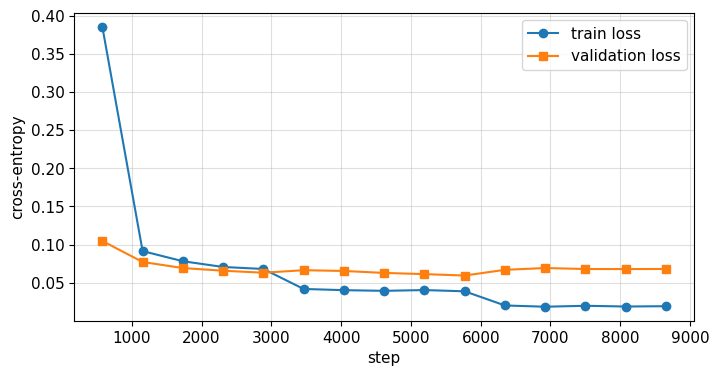

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** `LR = 2e-4` - маленькой модели (3 слоя, hidden 312) нужен lr больше, чем base-моделям с 2e-5 - 5e-5; batch 32 с запасом помещается в память T4; 3 эпохи на 92 тыс. предложений - около 8 700 шагов; warmup 10% и линейное затухание стабилизируют начало обучения; weight decay 0.01 - стандарт для BERT; fp16 ускоряет обучение на T4. По кривым train loss падает монотонно (0.068 к концу 1-й эпохи, 0.039 ко 2-й, 0.019 к 3-й), а validation loss достигает минимума 0.059 на 2-й эпохе и к концу 3-й растет до 0.068 (+14%): на 3-й эпохе есть легкое переобучение, больше эпох не нужно, скорее хватило бы двух (или ранней остановки по F1 на validation; рост loss при этом не обязательно значит падение F1 - модель становится увереннее на своих ошибках). Обучение заняло 297 с на Tesla T4 (около 930 предложений в секунду).

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_gold = n_pred = 0
    for gs, ps in zip(gold, pred):
        for g, p in zip(gs, ps):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += p != 'O' and p == g
    return 0.0 if tp == 0 else 2 * tp / (n_gold + n_pred)

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

val_pred = predict_word_tags(model, val_tokens)
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
for split, gold_tags, pred_tags in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(split)
    print(classification_report(gold_tags, pred_tags, digits=4, zero_division=0))
    print({k: round(v, 4) for k, v in entity_scores(gold_tags, pred_tags).items()},
          'token_f1', round(token_f1(gold_tags, pred_tags), 4), '\n')

report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = dict(entity_scores(test_gold, test_pred), token_f1=token_f1(test_gold, test_pred),
             per_type={t: {k: report[t][k] for k in ('precision', 'recall', 'f1-score', 'support')}
                       for t in ENTITY_TYPES if t in report})
final

validation
              precision    recall  f1-score   support

         LOC     0.9113    0.9241    0.9176      8851
        MISC     0.7242    0.7385    0.7313      2642
         ORG     0.7519    0.7863    0.7688      2710
         PER     0.8698    0.8805    0.8751      4007

   micro avg     0.8507    0.8671    0.8588     18210
   macro avg     0.8143    0.8323    0.8232     18210
weighted avg     0.8513    0.8671    0.8591     18210

{'f1_micro': np.float64(0.8588), 'f1_macro': np.float64(0.8232), 'precision': np.float64(0.8507), 'recall': np.float64(0.8671)} token_f1 0.8705 

test
              precision    recall  f1-score   support

         LOC     0.9179    0.9286    0.9232      8596
        MISC     0.7479    0.7562    0.7521      2962
         ORG     0.7377    0.7955    0.7655      3051
         PER     0.8719    0.8951    0.8833      3489

   micro avg     0.8496    0.8715    0.8604     18098
   macro avg     0.8188    0.8438    0.8310     18098
weighted avg     0.8508

{'f1_micro': np.float64(0.8604238836911159),
 'f1_macro': np.float64(0.831019637098843),
 'precision': np.float64(0.8496471475515811),
 'recall': np.float64(0.8714775113272185),
 'token_f1': 0.874944062487287,
 'per_type': {'LOC': {'precision': np.float64(0.9178932842686293),
   'recall': np.float64(0.9285714285714286),
   'f1-score': np.float64(0.9232014804533889),
   'support': np.int64(8596)},
  'MISC': {'precision': np.float64(0.7479131886477463),
   'recall': np.float64(0.7562457798784605),
   'f1-score': np.float64(0.7520564042303173),
   'support': np.int64(2962)},
  'ORG': {'precision': np.float64(0.7376899696048632),
   'recall': np.float64(0.7954768928220256),
   'f1-score': np.float64(0.7654944015139568),
   'support': np.int64(3051)},
  'PER': {'precision': np.float64(0.871859296482412),
   'recall': np.float64(0.8950988822012038),
   'f1-score': np.float64(0.8833262621977089),
   'support': np.int64(3489)}}}

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test F1 micro 0.860 (P 0.850, R 0.871), macro 0.831, токенный F1 0.875; по типам: LOC 0.923, PER 0.883, ORG 0.765, MISC 0.752. Хуже всего MISC и ORG: они реже (16% и 14% сущностей train), разнороднее (MISC - произведения, события, национальности и т.п.), длиннее (больше ошибок границ) и путаются с LOC (университеты, команды, страны как организации). Micro F1 на 3 п.п. выше macro, потому что micro взвешивает по числу сущностей, а почти половина из них (8 596 из 18 098) - LOC с лучшим F1; macro равно учитывает слабые MISC и ORG. Токенный F1 (0.875) выше F1 по сущностям (0.860): при ошибке границы спан целиком не засчитывается, а его правильно размеченные слова - засчитываются; разница небольшая, потому что большинство спанов однословные, и для них обе метрики совпадают. Пользователю NER ближе F1 по сущностям: ему нужно извлечь имя или название целиком, а не отдельные слова.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def overlap(a, b):
        return min(a[1], b[1]) - max(a[0], b[0])

    result = []
    for g in gold_spans:
        hits = sorted((p for p in pred_spans if overlap(g, p) > 0), key=lambda p: -overlap(g, p))
        same_type = [p for p in hits if p[2] == g[2]]
        exact = [p for p in same_type if p[:2] == g[:2]]
        if exact:
            result.append(('correct', g, exact[0]))
        elif same_type:
            result.append(('boundary', g, same_type[0]))
        elif hits:
            result.append(('type', g, hits[0]))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if all(overlap(g, p) <= 0 for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counts, by_type, examples = collections.Counter(), collections.defaultdict(collections.Counter), collections.defaultdict(list)
for i, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred)):
    for cat, g, p in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        counts[cat] += 1
        by_type[(g or p)[2]][cat] += 1
        if cat != 'correct' and len(examples[cat]) < 3:
            examples[cat].append((i, g, p))
errors = {c: counts[c] for c in ERROR_CATEGORIES}
n_errors = sum(v for c, v in errors.items() if c != 'correct')
print(errors)
print('доли среди ошибок:', {c: f'{errors[c] / max(n_errors, 1):.1%}' for c in ERROR_CATEGORIES if c != 'correct'})
print(f'\n{"type":<6}' + ''.join(f'{c:>10}' for c in ERROR_CATEGORIES))
for t in ENTITY_TYPES:
    print(f'{t:<6}' + ''.join(f'{by_type[t][c]:>10}' for c in ERROR_CATEGORIES))


def show_span(words, span):
    return 'None' if span is None else f'[{" ".join(words[span[0]:span[1]])}] {span[2]}'


for cat in ERROR_CATEGORIES[1:]:
    print(f'\n=== {cat}')
    for i, g, p in examples[cat]:
        print(' '.join(val_tokens[i]))
        print(f'   gold: {show_span(val_tokens[i], g)}   pred: {show_span(val_tokens[i], p)}')

{'correct': 15789, 'boundary': 672, 'type': 1376, 'missed': 373, 'spurious': 596}
доли среди ошибок: {'boundary': '22.3%', 'type': '45.6%', 'missed': '12.4%', 'spurious': '19.8%'}

type     correct  boundary      type    missed  spurious
LOC         8179       148       443        81       139
MISC        1951       191       323       177       280
ORG         2131       256       259        64        97
PER         3528        77       351        51        80

=== boundary
Позднее , в 2001 г. , он вновь возьмётся за театральную роль в хите лондонского Вест-Энда " « Кошка на раскалённой крыше » " Теннесси Уильямса .
   gold: [Теннесси Уильямса] PER   pred: [Уильямса] PER
В 2002 году Фрэйзер сыграл вторую главную роль в новой экранизации романа Грэма Грина « Тихий американец » с участием Майкла Кейна и в последующем обратился в творчестве к серьёзным ролям .
   gold: [Тихий американец »] MISC   pred: [« Тихий американец »] MISC
В 1962 - 1966 годах был профессором микробиологии и заведу

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation 15 789 спанов верные, ошибок 3 017: тип 1 376 (45.6%), граница 672 (22.3%), лишние спаны 596 (19.8%), пропуски 373 (12.4%). Самая частая - ошибка типа, в основном у однословных имен без подсказки в контексте (LOC 443, PER 351, MISC 323): персонаж «Ларго» предсказан как LOC, город «Веспрем» - как PER, семейство растений «Маревые» размечено в gold как LOC. Ошибки границ - в основном ORG (256) и MISC (191): включать ли родовое слово, имя или кавычки («Университета» против «Университета Питтсбурга», «Тихий американец »» с одной кавычкой в gold). Многие ошибки - на самом деле ошибки автоматической разметки: «Маревые» как LOC, «лев» как PER, неполный спан «Университета» без «Питтсбурга», а среди «лишних» спанов есть настоящие сущности без разметки («Водном кодексе»). Чтобы уменьшить ошибки типа, нужен более сильный контекст: большая модель (xlm-roberta-base в 6.2 дала F1 0.901 против 0.860), более длинный контекст (абзац вместо предложения), а для оценки - чистка или ручная перепроверка разметки validation.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
set_seed(SEED)
frozen_model = make_model()
history_frozen, RUN_TIMES['train_freeze_sec'] = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                                          freeze_encoder=True, out_dir='runs/freeze')
frozen_pred = predict_word_tags(frozen_model, val_tokens)


def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


ablation = dict(
    setting=ABLATION, split='validation',
    full=dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred),
              train_sec=RUN_TIMES['train_main_sec'], trainable_params=n_trainable(model)),
    freeze=dict(entity_scores(val_gold, frozen_pred), token_f1=token_f1(val_gold, frozen_pred),
                train_sec=RUN_TIMES['train_freeze_sec'], trainable_params=n_trainable(frozen_model)))
print(f'{"":<8}{"f1_micro":>10}{"f1_macro":>10}{"token_f1":>10}{"train, s":>10}{"trainable":>12}')
for name in ('full', 'freeze'):
    r = ablation[name]
    print(f'{name:<8}{r["f1_micro"]:>10.4f}{r["f1_macro"]:>10.4f}{r["token_f1"]:>10.4f}{r["train_sec"]:>10.1f}'
          f'{r["trainable_params"]:>12,}')
frozen_model.cpu()
del frozen_model

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.179', 'grad_norm': '0.4676', 'learning_rate': '0.0001332', 'epoch': '0.2'}
{'eval_loss': '0.3766', 'eval_runtime': '2.787', 'eval_samples_per_second': '4140', 'eval_steps_per_second': '64.94', 'epoch': '0.2'}
{'loss': '0.2963', 'grad_norm': '0.2244', 'learning_rate': '0.0001926', 'epoch': '0.4'}
{'eval_loss': '0.2276', 'eval_runtime': '2.799', 'eval_samples_per_second': '4123', 'eval_steps_per_second': '64.67', 'epoch': '0.4'}
{'loss': '0.2201', 'grad_norm': '0.2287', 'learning_rate': '0.0001778', 'epoch': '0.6'}
{'eval_loss': '0.1913', 'eval_runtime': '2.75', 'eval_samples_per_second': '4196', 'eval_steps_per_second': '65.81', 'epoch': '0.6'}
{'loss': '0.1988', 'grad_norm': '0.2206', 'learning_rate': '0.000163', 'epoch': '0.8'}
{'eval_loss': '0.1753', 'eval_runtime': '2.752', 'eval_samples_per_second': '4194', 'eval_steps_per_second': '65.78', 'epoch': '0.8'}
{'loss': '0.1877', 'grad_norm': '0.206', 'learning_rate': '0.0001482', 'epoch': '1'}
{'eval_loss': '0.1669', 'eval_

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** С замороженным энкодером F1 micro на validation упал с 0.859 до 0.633 (-22.6 п.п.), macro - с 0.823 до 0.539, токенный F1 - с 0.871 до 0.665; обучаемых параметров 2 817 (только голова, 312 x 9 + 9) против 29.1M, а время обучения сократилось лишь с 297 до 170 с (-43%), потому что прямой проход через весь энкодер и подготовка батчей остаются, экономится только backward и обновление энкодера. Train loss замороженной модели остановился около 0.17, validation около 0.15 - это недообучение, а не переобучение: признаки, полученные при предобучении, линейно плохо разделяют типы сущностей и `B-` / `I-`, энкодер нужно подстраивать под задачу. Чтобы вывод был надежнее, я бы повторил оба варианта на нескольких seed и проверил промежуточный вариант - разморозить только последний слой энкодера (и подобрать для головы свой lr по validation).

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообучение `rubert-tiny2` на 92 тыс. предложений WikiNEuRal ru за 5 минут на T4 подняло F1 по сущностям на validation с 0.029 (случайная голова) и 0.584 (словарный бейзлайн) до 0.859, на test - 0.860 (macro 0.831). Лучше всего распознаются LOC (0.923) и PER (0.883), хуже - MISC (0.752) и ORG (0.765); главная категория ошибок - тип сущности (45.6% ошибок), затем границы (22.3%). Полное дообучение необходимо: с замороженным энкодером F1 только 0.633. Большая модель окупается качеством: xlm-roberta-base дает 0.901 (+4.1 п.п.), но в 9.5 раза больше по параметрам и в 5.9 раза дольше учится. Модель очень хрупкая к регистру: в нижнем регистре F1 падает до 0.19, в верхнем - до 0.04, при транслите - до 0.21, а `torch.compile` ускоряет инференс в 2.1 раза без потери F1. Ограничения: один seed, автоматическая («silver») разметка с заметным шумом, отсутствие в данных предложений без сущностей и только википедийный домен. Дальше я бы сделал раннюю остановку по F1 (validation loss растет на 3-й эпохе), аугментацию регистром и опечатками, проверил несколько seed и оценил модель на вручную размеченных данных другого домена.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 92320, "n_val": 11540, "n_test": 11580, "params_total": 29098929, "ablation": {"setting": "freeze", "split": "validation", "full": {"f1_micro": 0.8588212896733661, "f1_macro": 0.8231938220620691, "precision": 0.8507462686567164, "recall": 0.8670510708401977, "token_f1": 0.8705275420203029, "train_sec": 297.407518802, "trainable_params": 29098929}, "freeze": {"f1_micro": 0.6331137043211346, "f1_mac
final F1 micro 0.8604


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    MODEL_ID_2 = 'FacebookAI/xlm-roberta-base'
    REVISION_2 = 'e73636d4f797dec63c3081bb6ed5c7b0bb3f2089'
    LR_2 = 3e-5
    tokenizer_2 = AutoTokenizer.from_pretrained(MODEL_ID_2, revision=REVISION_2)
    tokenized_2 = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                           fn_kwargs=dict(tok=tokenizer_2))
    set_seed(SEED)
    model_2 = make_model(MODEL_ID_2, REVISION_2)
    history_2, RUN_TIMES['train_model_2_sec'] = train_ner(model_2, tokenized_2['train'], tokenized_2['validation'],
                                                          lr=LR_2, tok=tokenizer_2, out_dir='runs/model_2')

    compare = {}
    for name, m, tok, lr, train_sec in [(MODEL_ID, model, tokenizer, LR, RUN_TIMES['train_main_sec']),
                                        (MODEL_ID_2, model_2, tokenizer_2, LR_2, RUN_TIMES['train_model_2_sec'])]:
        predict_word_tags(m, test_tokens[:64], tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        pred = predict_word_tags(m, test_tokens, tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        n = sum(p.numel() for p in m.parameters())
        compare[name] = dict(entity_scores(test_gold, pred), token_f1=token_f1(test_gold, pred), lr=lr, params=n,
                             size_mb=n * 4 / 2**20, train_sec=train_sec, infer_test_sec=time.perf_counter() - start)
    print(f'test, {len(test_tokens)} предложений, {DEVICE_NAME}')
    print(f'{"":<30}{"f1_micro":>10}{"f1_macro":>10}{"params":>14}{"MB fp32":>9}{"train, s":>10}{"infer, s":>10}')
    for name, r in compare.items():
        print(f'{name:<30}{r["f1_micro"]:>10.4f}{r["f1_macro"]:>10.4f}{r["params"]:>14,}{r["size_mb"]:>9.0f}'
              f'{r["train_sec"]:>10.1f}{r["infer_test_sec"]:>10.1f}')
    model_2.cpu()
    torch.cuda.empty_cache()

Map:   0%|          | 0/92320 [00:00<?, ? examples/s]

Map:   0%|          | 0/11540 [00:00<?, ? examples/s]

Map:   0%|          | 0/11580 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '0.4621', 'grad_norm': '3.245', 'learning_rate': '1.998e-05', 'epoch': '0.2'}
{'eval_loss': '0.08872', 'eval_runtime': '14.02', 'eval_samples_per_second': '823.2', 'eval_steps_per_second': '12.91', 'epoch': '0.2'}
{'loss': '0.07639', 'grad_norm': '1.265', 'learning_rate': '2.889e-05', 'epoch': '0.4'}
{'eval_loss': '0.06176', 'eval_runtime': '13.9', 'eval_samples_per_second': '830.1', 'eval_steps_per_second': '13.02', 'epoch': '0.4'}
{'loss': '0.06282', 'grad_norm': '1.778', 'learning_rate': '2.667e-05', 'epoch': '0.6'}
{'eval_loss': '0.05601', 'eval_runtime': '13.84', 'eval_samples_per_second': '833.8', 'eval_steps_per_second': '13.08', 'epoch': '0.6'}
{'loss': '0.05579', 'grad_norm': '1.243', 'learning_rate': '2.445e-05', 'epoch': '0.8'}
{'eval_loss': '0.05324', 'eval_runtime': '13.84', 'eval_samples_per_second': '834.1', 'eval_steps_per_second': '13.08', 'epoch': '0.8'}
{'loss': '0.05344', 'grad_norm': '0.9637', 'learning_rate': '2.222e-05', 'epoch': '1'}
{'eval_loss': '0.05

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** `xlm-roberta-base` лучше: на test F1 micro 0.901 против 0.860 (+4.1 п.п.), macro 0.880 против 0.831, минимум validation loss 0.042 против 0.059 и без заметного переобучения. Цена: 277M параметров против 29M (в 9.5 раза больше, 1 058 против 111 MB в fp32, а при обучении AdamW хранит еще два таких же буфера), обучение 1 746 против 297 с (в 5.9 раза дольше), разметка всего test - 18.9 против 9.2 с (в 2 раза; в это время входят токенизация и сборка тегов на CPU, поэтому разница меньше, чем в объеме вычислений). Честность сравнения: те же данные и сплиты, тот же `train_ner` (3 эпохи, batch 32, warmup 10%, weight decay 0.01, fp16, seed 0), та же оценка по первому сабворду на test и тот же T4; отличается только lr - стандартный для каждого размера (2e-4 и 3e-5), по test он не подбирался. Ограничение - один seed для каждой модели.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    TRANSLIT = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                        ['a', 'b', 'v', 'g', 'd', 'e', 'e', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r',
                         's', 't', 'u', 'f', 'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']))


    def translit(word):
        return ''.join((TRANSLIT[c.lower()].capitalize() if c.isupper() else TRANSLIT[c]) if c.lower() in TRANSLIT else c
                       for c in word)


    def typo(word, rng, p=0.3):
        if len(word) < 4 or rng.random() >= p:
            return word
        i = rng.randrange(len(word) - 1)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]


    rng = random.Random(SEED)
    corruptions = {'clean': lambda w: w, 'lower': str.lower, 'upper': str.upper,
                   'typos 30%': lambda w: typo(w, rng), 'translit': translit}
    shift = {}
    for name, fn in corruptions.items():
        tokens = [[fn(w) for w in ws] for ws in val_tokens]
        pred = predict_word_tags(model, tokens)
        report = classification_report(val_gold, pred, output_dict=True, zero_division=0)
        shift[name] = dict(entity_scores(val_gold, pred), per_type_f1={t: report[t]['f1-score'] for t in ENTITY_TYPES})
        print(f'{name:<10}', ' '.join(tokens[1][:12]))
    print(f'\n{"":<10}{"f1_micro":>10}{"precision":>10}{"recall":>10}' + ''.join(f'{t:>8}' for t in ENTITY_TYPES))
    for name, r in shift.items():
        print(f'{name:<10}{r["f1_micro"]:>10.4f}{r["precision"]:>10.4f}{r["recall"]:>10.4f}'
              + ''.join(f'{r["per_type_f1"][t]:>8.3f}' for t in ENTITY_TYPES))

clean      В это время территория была под властью фригийцев и позже перешла к
lower      в это время территория была под властью фригийцев и позже перешла к
upper      В ЭТО ВРЕМЯ ТЕРРИТОРИЯ БЫЛА ПОД ВЛАСТЬЮ ФРИГИЙЦЕВ И ПОЗЖЕ ПЕРЕШЛА К
typos 30%  В это время территория была под властью фригийцев и позеж перешла к
translit   V eto vremya territoriya byla pod vlastyu frigiytsev i pozzhe pereshla k

            f1_micro precision    recall     LOC    MISC     ORG     PER
clean         0.8588    0.8507    0.8671   0.918   0.731   0.769   0.875
lower         0.1935    0.2695    0.1509   0.133   0.264   0.261   0.107
upper         0.0409    0.0401    0.0417   0.039   0.073   0.044   0.000
typos 30%     0.7844    0.7890    0.7798   0.854   0.654   0.680   0.788
translit      0.2063    0.3016    0.1568   0.165   0.201   0.194   0.277


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** На validation при чистом тексте F1 0.859; опечатки в 30% слов снижают его до 0.784 (-7.4 п.п.), транслит - до 0.206, нижний регистр - до 0.194, верхний - до 0.041. Сильнее всего бьет верхний регистр: модель cased, и заглавная буква - главный признак имени собственного; когда заглавными написаны все слова, этот признак исчезает, а слова режутся на редкие «заглавные» сабворды, которых модель почти не видела (P 0.040, R 0.042). Нижний регистр убирает тот же признак, и модель перестает находить сущности (recall 0.151); при транслите текст становится латиницей, на которой модель для русского почти не обучена, лучше всего держатся PER (0.277) - у имен остаются заглавные буквы. Опечатки вредят слабо, потому что регистр и большая часть сабвордов сохраняются, сильнее страдают MISC и ORG (0.654 и 0.680). Помочь могла бы аугментация при обучении: случайная смена регистра, опечатки и транслит части примеров.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    bench = {k: v.to(device) for k, v in tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True,
                                                   max_length=MAX_LENGTH, padding=True, return_tensors='pt').items()}
    model.eval().to(device)


    def latency_ms(fn, n=50):
        with torch.inference_mode():
            for _ in range(5):
                fn()
            if device.type == 'cuda':
                torch.cuda.synchronize()
            start = time.perf_counter()
            for _ in range(n):
                fn()
            if device.type == 'cuda':
                torch.cuda.synchronize()
        return (time.perf_counter() - start) / n * 1000


    def run_fp16():
        with torch.autocast(device.type, dtype=torch.float16):
            return model(**bench)


    compiled = torch.compile(model, dynamic=True)
    start = time.perf_counter()
    with torch.inference_mode():
        compiled(**bench)
    compile_sec = time.perf_counter() - start

    speed = {'eager fp32': dict(latency_ms=latency_ms(lambda: model(**bench)), f1_micro=entity_scores(val_gold, val_pred)['f1_micro']),
             'torch.compile': dict(latency_ms=latency_ms(lambda: compiled(**bench)),
                                   f1_micro=entity_scores(val_gold, predict_word_tags(compiled, val_tokens))['f1_micro'])}
    with torch.autocast(device.type, dtype=torch.float16):
        f1_fp16 = entity_scores(val_gold, predict_word_tags(model, val_tokens))['f1_micro']
    speed['fp16 autocast'] = dict(latency_ms=latency_ms(run_fp16), f1_micro=f1_fp16)
    print(f'батч {tuple(bench["input_ids"].shape)} на {DEVICE_NAME}, компиляция {compile_sec:.1f} s')
    print(f'{"":<16}{"latency, ms":>12}{"speedup":>9}{"F1 val":>9}')
    for name, r in speed.items():
        print(f'{name:<16}{r["latency_ms"]:>12.2f}{speed["eager fp32"]["latency_ms"] / r["latency_ms"]:>8.2f}x{r["f1_micro"]:>9.4f}')

W1119 12:49:57.195000 3029 torch/_inductor/utils.py:1806] [0/1] Not enough SMs to use max_autotune_gemm mode


батч (32, 65) на Tesla T4, компиляция 13.4 s
                 latency, ms  speedup   F1 val
eager fp32              5.97    1.00x   0.8588
torch.compile           2.81    2.12x   0.8588
fp16 autocast           6.08    0.98x   0.8588


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** На Tesla T4, батч 32 x 65 сабвордов, среднее по 50 запускам после прогрева: eager fp32 - 5.97 мс, `torch.compile` - 2.81 мс (ускорение в 2.12 раза, компиляция заняла 13.4 с), fp16 autocast - 6.08 мс (0.98x, выигрыша нет). F1 на validation не изменился ни в одном варианте (0.8588). У `rubert-tiny2` 92% параметров - таблица эмбеддингов, а это просто поиск строк без вычислений; в энкодере всего 2.3M параметров и матрицы 312 x 312, поэтому GPU недогружен, и время уходит на накладные расходы запуска десятков мелких kernel-ов, а не на арифметику. `torch.compile` сливает операции и сокращает число запусков - отсюда ускорение; fp16 ускоряет только матричные умножения, которые здесь и так дешевые, и добавляет приведения типов. У тяжелой по вычислениям модели (например, xlm-roberta-base с 12 слоями по 768) выигрыш от fp16 был бы заметно больше.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean  порог 0: F1 0.8588 (P 0.8507, R 0.8671);  лучший порог 0.74: F1 0.8632 (P 0.8965, R 0.8322), +0.0044
min   порог 0: F1 0.8588 (P 0.8507, R 0.8671);  лучший порог 0.60: F1 0.8633 (P 0.8797, R 0.8475), +0.0045
seqeval F1 micro на validation (порог 0): 0.8588


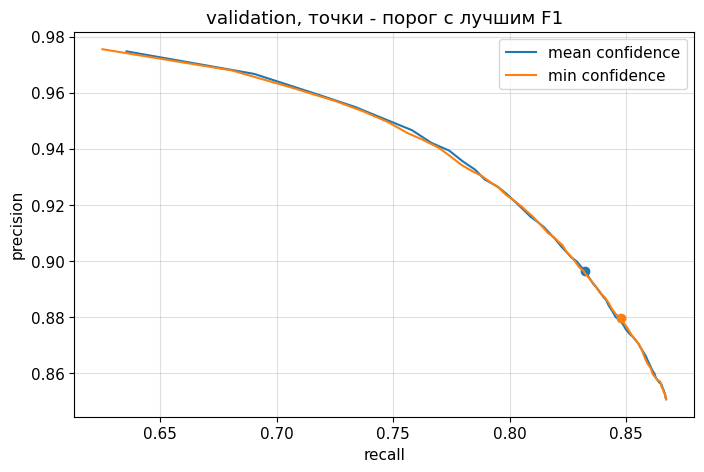

In [34]:
if '6.5' in BONUS_TASKS:
    tags_v, probs_v = predict_word_tags(model, val_tokens, return_probs=True)
    gold_spans = [set(bio_to_spans(g)) for g in val_gold]
    n_gold = sum(len(s) for s in gold_spans)
    conf_mean, conf_min, hit = [], [], []
    for tags, probs, gs in zip(tags_v, probs_v, gold_spans):
        for s, e, t in bio_to_spans(tags):
            conf_mean.append(np.mean(probs[s:e]))
            conf_min.append(min(probs[s:e]))
            hit.append((s, e, t) in gs)
    hit = np.array(hit)
    thresholds = np.round(np.linspace(0, 0.99, 100), 2)

    plt.figure(figsize=(8, 5))
    thresholds_best = {}
    for name, conf in [('mean', np.array(conf_mean)), ('min', np.array(conf_min))]:
        keep = conf[None, :] >= thresholds[:, None]
        tp = (keep & hit[None, :]).sum(1)
        precision = tp / np.maximum(keep.sum(1), 1)
        recall = tp / max(n_gold, 1)
        f1 = np.where(tp > 0, 2 * precision * recall / np.maximum(precision + recall, 1e-12), 0)
        b = int(f1.argmax())
        thresholds_best[name] = dict(threshold=float(thresholds[b]), f1=float(f1[b]), precision=float(precision[b]),
                                     recall=float(recall[b]), f1_at_0=float(f1[0]))
        print(f'{name:<5} порог 0: F1 {f1[0]:.4f} (P {precision[0]:.4f}, R {recall[0]:.4f});  '
              f'лучший порог {thresholds[b]:.2f}: F1 {f1[b]:.4f} (P {precision[b]:.4f}, R {recall[b]:.4f}), '
              f'+{f1[b] - f1[0]:.4f}')
        line, = plt.plot(recall, precision, label=f'{name} confidence')
        plt.plot(recall[b], precision[b], 'o', color=line.get_color())
    print(f'seqeval F1 micro на validation (порог 0): {entity_scores(val_gold, tags_v)["f1_micro"]:.4f}')
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.title('validation, точки - порог с лучшим F1')
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** При средней уверенности лучший порог 0.74: F1 0.8632 против 0.8588 при пороге 0 (+0.44 п.п.), precision растет с 0.851 до 0.897, recall падает с 0.867 до 0.832; при минимальной - порог 0.60, F1 0.8633 (+0.45 п.п., P 0.880, R 0.848). Средняя и минимальная уверенность различаются только у многословных спанов: минимальная отсекает спан, если хотя бы одно слово неуверенное, она строже, поэтому тот же эффект достигается при меньшем пороге; у однословных спанов (большинство в датасете) они совпадают. Порог не может поднять recall: он только убирает предсказанные спаны, а новых не добавляет, поэтому число верных спанов может только уменьшиться. Порог подбирался на validation, его стоит перепроверить на test.